# 08. Giải thích và sử dụng mô hình

Giải thích CatBoost 182 biến đã chốt sau Feature Selection: tầm quan trọng toàn cục, các hồ sơ báo nhầm/bỏ sót và mức tập trung rủi ro theo score. Cuối notebook nạp đúng artifact mới để chấm năm hồ sơ chưa có nhãn.

Mô hình dùng raw score và ngưỡng 14,5394% đã chọn trên validation ở notebook 07. Validation và test lịch sử được trình bày riêng; các phân tích tại đây không chọn lại mô hình hoặc ngưỡng. Dashboard hiện vẫn dùng phiên bản đã triển khai trước đó.


## Mục lục

- [01. Đọc phiên bản mô hình](#part-1)
- [02. Tầm quan trọng đặc trưng toàn cục](#part-2)
- [03. Hồ sơ báo nhầm và bỏ sót](#part-3)
- [04. Precision–Recall, gains và decile](#part-4)
- [05. Minh họa tải mô hình và chấm điểm](#part-5)

<a id="part-1"></a>

## 01. Đọc phiên bản mô hình

Đọc quyết định chốt cho đồ án và metadata đi kèm artifact 182 biến. Đối chiếu mã SHA-256 của model, số biến và ngưỡng với quyết định đã lưu trước khi phân tích các dự báo.


In [1]:
from pathlib import Path
import json
import sys
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import precision_recall_curve, average_precision_score

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from models.CreditRiskModel import CreditRiskModel
from models.HomeCreditTraining import HomeCreditTraining

EVALUATION = ROOT / 'reports/modeling/selected_model_evaluation_20261030'
decision = json.loads((EVALUATION / 'project_model_decision.json').read_text(encoding='utf-8'))
metadata_path = ROOT / decision['metadata_path']
metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
assert hashlib.sha256((ROOT / metadata['model_path']).read_bytes()).hexdigest() == decision['model_sha256']
assert len(metadata['feature_order']) == decision['feature_count'] == 182
assert metadata['main_threshold'] == decision['threshold']
risk_model = CreditRiskModel(ROOT).loadModel(metadata_path)
REPORTS = EVALUATION / 'interpretation'
FIGURES = REPORTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 11, 'axes.grid': False, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': 'white'})
display(pd.DataFrame([{'model': metadata['display_name'], 'version': metadata['model_version'],
    'features': len(metadata['feature_order']), 'threshold': risk_model.threshold}]))


,model,version,features,threshold
0,CatBoost — Filter 182,catboost-selected-a8763faa0c2ef0786f72,182,0.145394


**Kết luận:** artifact và metadata khớp bản chốt 182 biến. Tất cả kết quả bên dưới thuộc phiên bản này, dùng ngưỡng đã chọn ở notebook 07.


<a id="part-2"></a>

## 02. Tầm quan trọng đặc trưng toàn cục

CatBoost dùng PredictionValuesChange để mô tả đóng góp của biến trong mô hình đã fit. Giá trị importance không cho biết quan hệ nhân quả hoặc chiều tác động đối với mọi hồ sơ.

,feature,value
35,EXT_SOURCE_3,14.565412
34,EXT_SOURCE_2,13.700374
33,EXT_SOURCE_1,5.413666
110,AGE_YEARS,3.594384
175,INS_PERIOD_WITH_AFTER_DUE_PAYMENT_SHARE,3.311715
117,RATIO_CREDIT_GOODS_RECORDED,3.051708
155,POS_FUTURE_INST_MEAN,2.363238
1,CODE_GENDER,2.225467
111,EMPLOYED_YEARS,2.158158
149,PREV_APPROVED_PAYMENT_COUNT_MEAN,1.991732


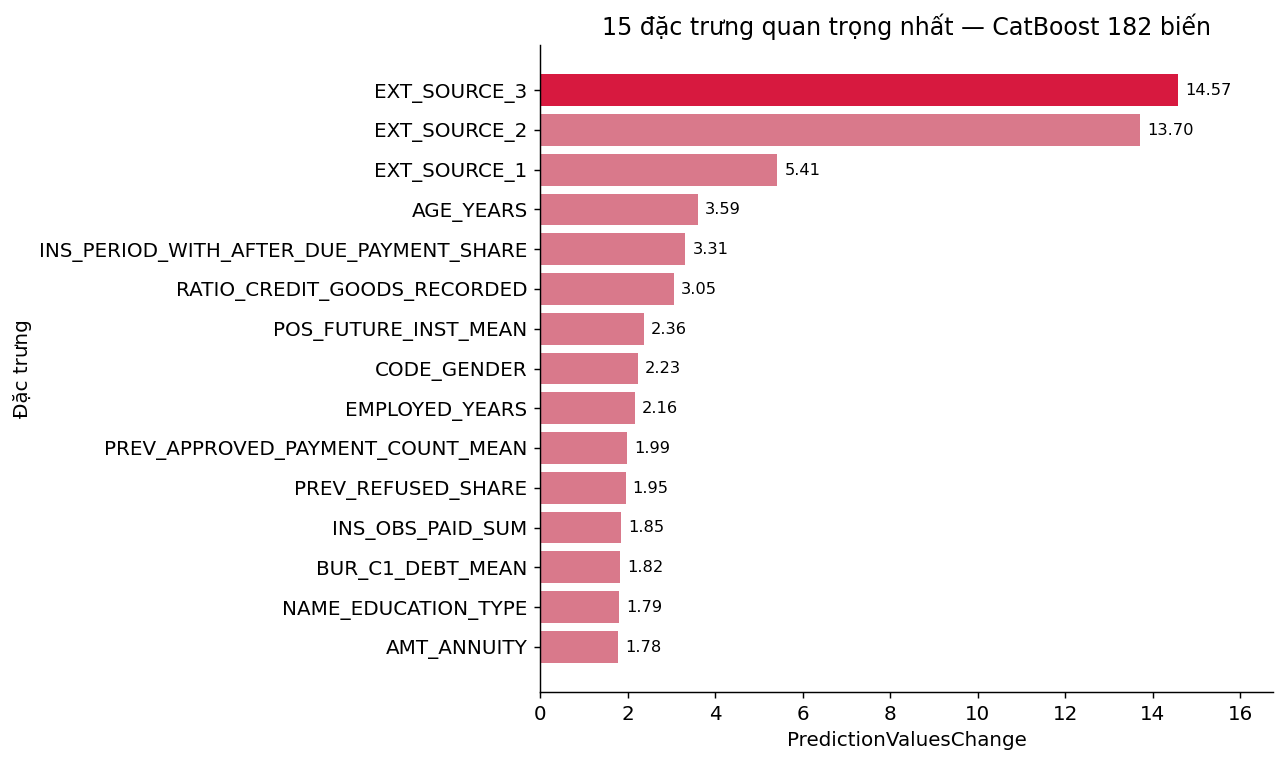

In [2]:
base_model = risk_model.model
importance = pd.DataFrame({'feature': base_model.feature_names_,
    'value': base_model.get_feature_importance(type='PredictionValuesChange')})
assert importance['feature'].tolist() == metadata['feature_order']
importance = importance.sort_values('value', ascending=False)
importance.to_csv(REPORTS / 'feature_importance.csv', index=False)
top_importance = importance.head(15)
display(top_importance)
fig, ax = plt.subplots(figsize=(10, 6))
rows = top_importance.sort_values('value')
colors = ['#D7193F' if f == top_importance.iloc[0]['feature'] else '#D9798B' for f in rows['feature']]
ax.barh(rows['feature'], rows['value'], color=colors)
ax.bar_label(ax.containers[0], fmt='%.2f', padding=4, fontsize=9)
ax.set(xlabel='PredictionValuesChange', ylabel='Đặc trưng',
       title='15 đặc trưng quan trọng nhất — CatBoost 182 biến')
ax.set_xlim(0, rows['value'].max() * 1.15)
fig.tight_layout()
for ext in ['png', 'pdf']:
    fig.savefig(FIGURES / ('feature_importance.' + ext), dpi=220, bbox_inches='tight')
plt.show()


**Kết luận:** bảng importance được tính trực tiếp từ model mới. Biến đứng cao có vai trò lớn trong mô hình đã fit; thứ hạng không cho biết chiều tác động cho từng hồ sơ và không chứng minh quan hệ nhân quả.


<a id="part-3"></a>

## 03. Hồ sơ báo nhầm và bỏ sót

Dùng ngưỡng đã chốt để xem một số false positive và false negative trên test lịch sử. Đây là ví dụ để tìm vấn đề cần kiểm tra ở train trong một thực nghiệm tiếp theo.

In [3]:
frozen = json.loads((EVALUATION / 'final_decision_before_test.json').read_text(encoding='utf-8'))
assert frozen['model_path'] == metadata['model_path']
assert frozen['feature_order'] == metadata['feature_order']
assert frozen['threshold'] == metadata['main_threshold']
test_predictions = pd.read_parquet(EVALUATION / 'historical_test_predictions.parquet').set_index('SK_ID_CURR')
alerts = test_predictions['score'] >= risk_model.threshold
false_positives = test_predictions.loc[alerts & test_predictions['TARGET'].eq(0)].nlargest(5, 'score').copy()
false_negatives = test_predictions.loc[~alerts & test_predictions['TARGET'].eq(1)].nsmallest(5, 'score').copy()
false_positives['error'] = 'FP'
false_negatives['error'] = 'FN'
error_examples = pd.concat([false_positives, false_negatives])
context = pd.read_parquet(ROOT / 'data/features/b/test.parquet').set_index('SK_ID_CURR')
context_columns = ['NAME_CONTRACT_TYPE', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'EXT_SOURCE_2']
error_examples = error_examples.join(context[context_columns], how='left')
error_examples.to_csv(REPORTS / 'error_examples.csv')
display(error_examples)


,TARGET,score,error,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,EXT_SOURCE_2
SK_ID_CURR,,,,,,,,
440774,0,0.726293,FP,Cash loans,36000.0,90000.0,8383.5,0.021195
269349,0,0.709636,FP,Cash loans,180000.0,587619.0,18954.0,0.328578
427557,0,0.703698,FP,Cash loans,112500.0,269550.0,21294.0,0.041721
407492,0,0.697075,FP,Cash loans,36000.0,814041.0,23931.0,0.058889
375724,0,0.686761,FP,Cash loans,45000.0,270000.0,12586.5,0.097247
205817,1,0.006148,FN,Cash loans,85500.0,159264.0,5571.0,0.682884
203427,1,0.007150,FN,Cash loans,135000.0,765000.0,22495.5,0.670909
405587,1,0.007376,FN,Revolving loans,162000.0,135000.0,6750.0,0.675628
135697,1,0.008034,FN,Revolving loans,157500.0,135000.0,6750.0,0.710660


**Kết luận:** các hồ sơ được chọn minh họa hai loại sai số tại ngưỡng cố định. Đây là các ví dụ có chủ đích ở hai đầu score, không đại diện cho mọi hồ sơ sai và không đủ để suy ra nguyên nhân sai hoặc điều chỉnh model từ test.


<a id="part-4"></a>

## 04. Precision–Recall, gains và decile

Các biểu đồ dưới đây mô tả mức độ tập trung TARGET = 1 theo thứ tự score. Decile 1 là nhóm có score cao nhất; các nhóm này không tự tạo thành quy tắc duyệt hay từ chối.

In [4]:
validation = pd.read_parquet(EVALUATION / 'validation_predictions.parquet')
historical_test = pd.read_parquet(EVALUATION / 'historical_test_predictions.parquet')
datasets = [('validation', validation, risk_model.threshold),
            ('historical_internal_test', historical_test, risk_model.threshold)]


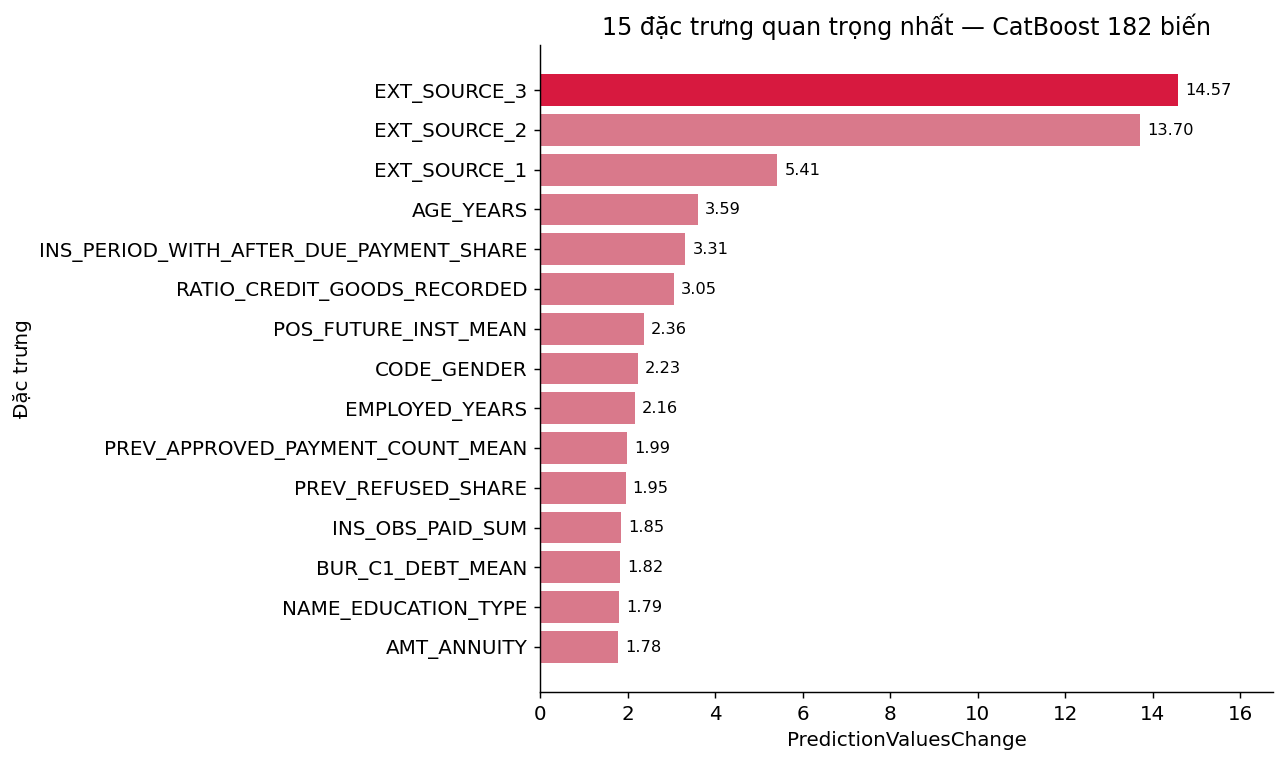

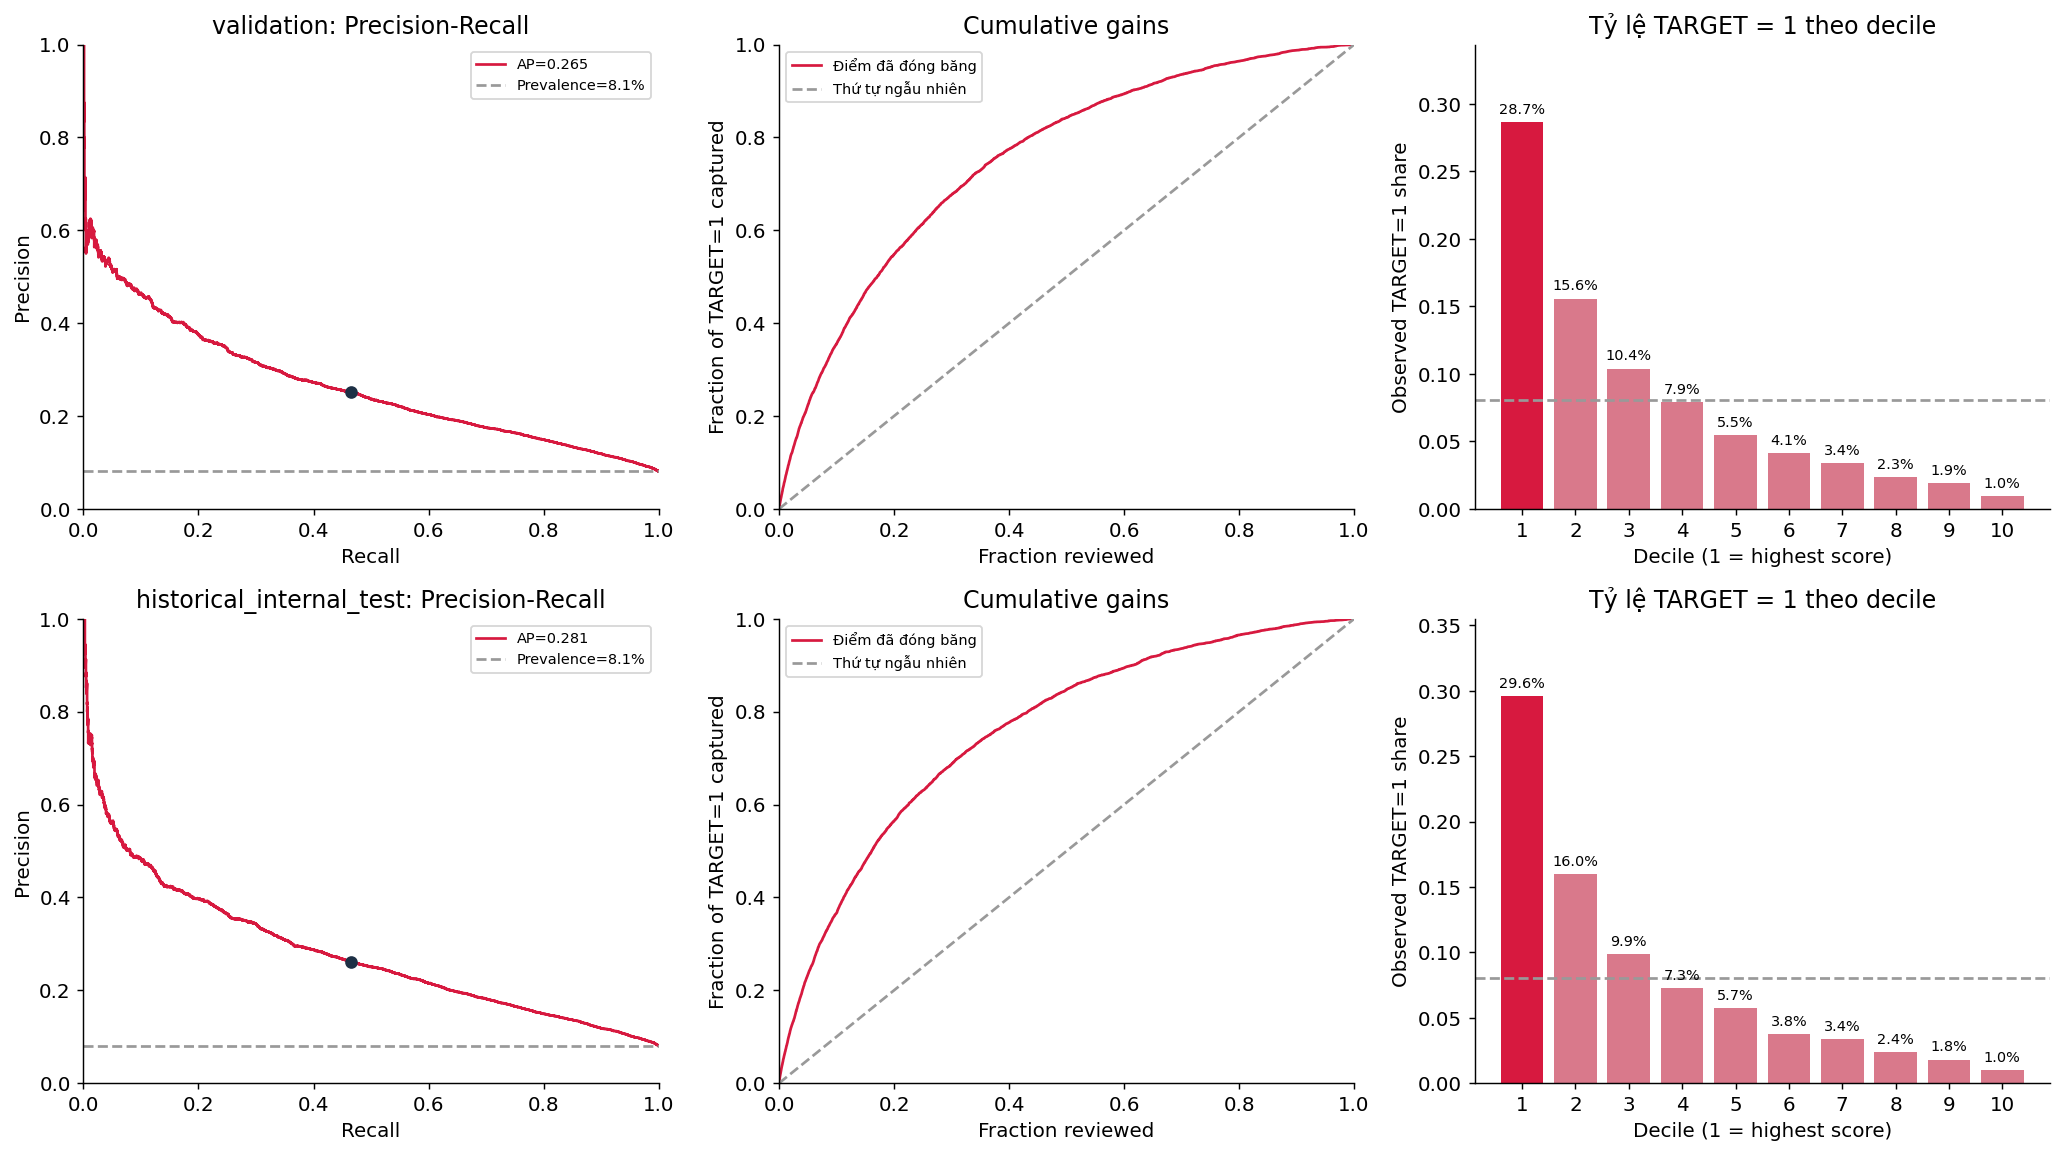

,dataset,fraction,review_n,captured_positive_n,false_alerts_n,missed_positive_n,precision,recall,lift,random_expected_positive_n
0,validation,0.01,616,307,309,4658,0.498377,0.061833,6.173446,49.729115
1,validation,0.05,3076,1107,1969,3858,0.359883,0.222961,4.457910,248.322656
2,validation,0.10,6151,1763,4388,3202,0.286620,0.355086,3.550394,496.564583
3,validation,0.20,12301,2721,9580,2244,0.221202,0.548036,2.740048,993.048437
4,historical_internal_test,0.01,616,322,294,4643,0.522727,0.064854,6.475185,49.728306
5,historical_internal_test,0.05,3076,1160,1916,3805,0.377113,0.233635,4.671418,248.318619
6,historical_internal_test,0.10,6151,1820,4331,3145,0.295887,0.366566,3.665242,496.556509
7,historical_internal_test,0.20,12301,2805,9496,2160,0.228030,0.564955,2.824682,993.032291


,dataset,decile,n,positive_n,positive_rate,lift,cumulative_review_n,cumulative_captured_n,cumulative_recall,min_score,max_score,mean_score
0,validation,1,6151,1763,0.286620,3.550394,6151,1763,0.355086,0.182774,0.906207,0.285572
1,validation,2,6150,958,0.155772,1.929569,12301,2721,0.548036,0.118676,0.182761,0.146555
2,validation,3,6150,639,0.103902,1.287051,18451,3360,0.676737,0.086338,0.118660,0.100944
3,validation,4,6150,487,0.079187,0.980898,24601,3847,0.774824,0.066097,0.086335,0.075601
4,validation,5,6150,337,0.054797,0.678773,30751,4184,0.842699,0.051451,0.066089,0.058435
5,validation,6,6151,253,0.041132,0.509501,36902,4437,0.893656,0.040368,0.051449,0.045652
6,validation,7,6150,208,0.033821,0.418946,43052,4645,0.935549,0.031529,0.040366,0.035838
7,validation,8,6150,143,0.023252,0.288025,49202,4788,0.964350,0.023950,0.031528,0.027681
8,validation,9,6150,117,0.019024,0.235657,55352,4905,0.987915,0.016755,0.023949,0.020346
9,validation,10,6150,60,0.009756,0.120850,61502,4965,1.000000,0.003208,0.016754,0.012346


,dataset,false_discovery_rate,false_positive_rate,below_threshold_positive_rate
0,validation,0.747901,0.121319,0.050697
1,historical_internal_test,0.739513,0.115993,0.050442


In [5]:
capacity_rows, decile_rows, metrics_rows = [], [], []
fig, axes = plt.subplots(len(datasets), 3, figsize=(16, 4.5 * len(datasets)), squeeze=False)
for panel, (name, data, threshold) in enumerate(datasets):
    assert data['SK_ID_CURR'].is_unique and data['TARGET'].isin([0, 1]).all()
    assert np.isfinite(data['score']).all() and data['score'].between(0, 1).all()
    rank = data.sort_values(['score', 'SK_ID_CURR'], ascending=[False, True], kind='stable').reset_index(drop=True)
    n, positives = len(rank), int(rank['TARGET'].sum())
    rate = positives / n
    metrics = HomeCreditTraining.policyMetrics(data['TARGET'], data['score'], threshold, name, 'fixed_frozen_threshold')
    metrics.update({'false_discovery_rate': metrics['fp'] / (metrics['tp'] + metrics['fp']),
        'false_positive_rate': metrics['fp'] / (metrics['fp'] + metrics['tn']),
        'false_negative_rate': metrics['fn'] / (metrics['tp'] + metrics['fn']),
        'below_threshold_positive_rate': metrics['fn'] / (metrics['tn'] + metrics['fn']),
        'above_threshold_lift': metrics['precision'] / rate, 'prevalence': rate})
    metrics_rows.append(metrics)
    for fraction in [.01, .05, .10, .20]:
        row = HomeCreditTraining.capacityMetrics(data['SK_ID_CURR'], data['TARGET'], data['score'], name, fraction)
        capacity_rows.append({'dataset': name, 'fraction': fraction, 'review_n': row['review_n'],
            'captured_positive_n': row['captured_positive_n'],
            'false_alerts_n': row['review_n'] - row['captured_positive_n'],
            'missed_positive_n': positives - row['captured_positive_n'],
            'precision': row['precision'], 'recall': row['recall'], 'lift': row['lift'],
            'random_expected_positive_n': row['review_n'] * rate})
    edges = [int(np.ceil(fraction * n / 10)) for fraction in range(11)]
    for decile in range(10):
        group = rank.iloc[edges[decile]:edges[decile + 1]]
        captured = int(group['TARGET'].sum())
        cumulative = int(rank.iloc[:edges[decile + 1]]['TARGET'].sum())
        decile_rows.append({'dataset': name, 'decile': decile + 1, 'n': len(group),
            'positive_n': captured, 'positive_rate': captured / len(group),
            'lift': captured / len(group) / rate,
            'cumulative_review_n': edges[decile + 1], 'cumulative_captured_n': cumulative,
            'cumulative_recall': cumulative / positives,
            'min_score': float(group['score'].min()), 'max_score': float(group['score'].max()),
            'mean_score': float(group['score'].mean())})
    assert sum(row['n'] for row in decile_rows if row['dataset'] == name) == n
    assert sum(row['positive_n'] for row in decile_rows if row['dataset'] == name) == positives
    precision, recall, _ = precision_recall_curve(data['TARGET'], data['score'])
    axes[panel, 0].plot(recall, precision, color='#D7193F', label=f'AP={average_precision_score(data.TARGET, data.score):.3f}')
    axes[panel, 0].axhline(rate, color='#999', linestyle='--', label=f'Prevalence={rate:.1%}')
    axes[panel, 0].scatter([metrics['recall']], [metrics['precision']], color='#1D3045', zorder=3)
    axes[panel, 0].set(xlabel='Recall', ylabel='Precision', title=f'{name}: Precision-Recall', xlim=(0, 1), ylim=(0, 1))
    axes[panel, 0].legend(fontsize=8)
    cumulative = np.cumsum(rank['TARGET'].to_numpy()) / positives
    fraction = np.arange(1, n + 1) / n
    axes[panel, 1].plot(fraction, cumulative, color='#D7193F', label='Điểm đã đóng băng')
    axes[panel, 1].plot([0, 1], [0, 1], color='#999', linestyle='--', label='Thứ tự ngẫu nhiên')
    axes[panel, 1].set(xlabel='Fraction reviewed', ylabel='Fraction of TARGET=1 captured', title='Cumulative gains', xlim=(0, 1), ylim=(0, 1))
    axes[panel, 1].legend(fontsize=8)
    rows = [row for row in decile_rows if row['dataset'] == name]
    axes[panel, 2].bar([row['decile'] for row in rows], [row['positive_rate'] for row in rows], color=['#D7193F'] + ['#D9798B'] * 9)
    axes[panel, 2].bar_label(axes[panel, 2].containers[0], labels=[f"{row['positive_rate']:.1%}" for row in rows], padding=3, fontsize=8)
    axes[panel, 2].set_ylim(0, max(row['positive_rate'] for row in rows) * 1.2)
    axes[panel, 2].axhline(rate, color='#999', linestyle='--')
    axes[panel, 2].set(xlabel='Decile (1 = highest score)', ylabel='Observed TARGET=1 share', title='Tỷ lệ TARGET = 1 theo decile', xticks=range(1, 11))

fig.tight_layout()
for ext in ['png', 'pdf']:
    fig.savefig(FIGURES / ('ranking_and_deciles.' + ext), dpi=220, bbox_inches='tight')
plt.show()
plt.close(fig)
display(pd.DataFrame(capacity_rows))
display(pd.DataFrame(decile_rows))
display(pd.DataFrame(metrics_rows)[['dataset', 'false_discovery_rate', 'false_positive_rate', 'below_threshold_positive_rate']])

pd.DataFrame(capacity_rows).to_csv(REPORTS / 'capacity_metrics.csv', index=False)
pd.DataFrame(decile_rows).to_csv(REPORTS / 'risk_deciles.csv', index=False)
pd.DataFrame(metrics_rows).to_csv(REPORTS / 'policy_diagnostics.csv', index=False)


**Kết luận:** decile 1 chứa 10% hồ sơ có score cao nhất; tỷ lệ TARGET = 1 trong nhóm là kết quả quan sát, không phải ngưỡng duyệt hoặc từ chối. Gains và lift giúp xem lượng rủi ro tìm được khi giới hạn số hồ sơ rà soát.


<a id="part-5"></a>

## 05. Minh họa tải mô hình và chấm điểm

Nạp metadata của model 182 biến đã chốt, lấy đúng các cột theo schema rồi chấm năm hồ sơ chưa có nhãn. Ví dụ kiểm tra cả việc nạp artifact và quy trình chuẩn bị đầu vào. Điểm số và cờ cảnh báo hỗ trợ rà soát, chưa phải quyết định cho vay.


In [6]:
risk_model = CreditRiskModel(ROOT).loadModel(metadata_path)
sample = pd.read_parquet(ROOT / 'data/features/b/application_test.parquet',
    columns=['SK_ID_CURR'] + risk_model.feature_order).set_index('SK_ID_CURR').head(5)
prepared_sample = risk_model.prepareInput(sample)
sample_predictions = risk_model.predict(prepared_sample)
sample_predictions.to_csv(REPORTS / 'sample_predictions.csv')
display(sample_predictions)


,score,threshold,alert
SK_ID_CURR,,,
100001,0.057181,0.145394,False
100005,0.153510,0.145394,True
100013,0.024389,0.145394,False
100028,0.022541,0.145394,False
100038,0.108874,0.145394,False


**Kết luận:** năm hồ sơ được chấm bằng model 182 biến qua `CreditRiskModel`, đúng thứ tự cột và ngưỡng đã chốt. Ví dụ chỉ xuất kết quả trong notebook và file CSV; chưa đăng ký model hay tạo lịch sử chấm điểm trong ứng dụng.


**Kết luận:** notebook đã được cập nhật và thực thi bằng CatBoost 182 biến, raw score, ngưỡng 14,5394%. Ba biến đứng đầu theo PredictionValuesChange là `EXT_SOURCE_3` (14.57), `EXT_SOURCE_2` (13.70) và `EXT_SOURCE_1` (5.41). Đây là mức quan trọng toàn cục trong model, không phải đóng góp riêng của từng hồ sơ hoặc quan hệ nhân quả.

Trên validation, top 10% score có tỷ lệ TARGET = 1 là **28.66%**, tìm được **35.51%** tổng số ca TARGET = 1 và lift **3.55 lần**. Các chỉ số tương ứng trên test lịch sử là **29.59%**, **36.66%** và **3.67 lần**. Khả năng tập trung rủi ro hỗ trợ phân bổ lượt rà soát; chưa đủ để tự thiết lập chính sách cho vay.

Đã lưu importance của toàn bộ 182 biến, 10 ví dụ sai số, bảng decile/capacity và kết quả chấm năm hồ sơ chưa có nhãn trong `reports/modeling/selected_model_evaluation_20261030/interpretation/`. Biểu đồ được xuất PNG/PDF; ví dụ nạp model dùng metadata riêng của bản đã chốt.

Notebook 05–08 hiện thống nhất cùng quy trình sau Feature Selection. Tích hợp artifact đã chốt lên dashboard là công việc tiếp theo. Các kết quả test được ghi rõ là lịch sử và không được dùng để chọn lại model hoặc ngưỡng.

